<a href="https://colab.research.google.com/github/antonioguizar-collab/Actividad3BDManipulacion/blob/main/ACTIVIDAD4EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm

# Cargar el dataset haciendo que 'ID' sea el índice inicial
loan_df = pd.read_csv('personal_loan.csv', index_col='ID')

# Mostrar resumen de tipos de datos
loan_df.info()

# Respuestas rápidas para el reporte:
print("\n--- Resumen de Columnas ---")
print("Columnas numéricas:", len(loan_df.select_dtypes(include=['int64', 'float64']).columns))
print("Columnas de texto (object):", len(loan_df.select_dtypes(include=['object']).columns))

<class 'pandas.core.frame.DataFrame'>
Index: 5037 entries, 0 to 5036
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Age                 5037 non-null   int64  
 1   Experience          5037 non-null   int64  
 2   Income              5037 non-null   int64  
 3   ZIP Code            5037 non-null   int64  
 4   Family              5037 non-null   int64  
 5   CCAvg               5037 non-null   float64
 6   Education           5037 non-null   float64
 7   Mortgage            5037 non-null   int64  
 8   Personal Loan       5037 non-null   object 
 9   Securities Account  5037 non-null   object 
 10  CD Account          5037 non-null   object 
 11  Online              5037 non-null   object 
 12  CreditCard          5037 non-null   object 
dtypes: float64(2), int64(6), object(5)
memory usage: 550.9+ KB

--- Resumen de Columnas ---
Columnas numéricas: 8
Columnas de texto (object): 5


In [3]:
# Estadísticas descriptivas iniciales
display(loan_df.describe())

total_inicial = len(loan_df)

# Filtrar y eliminar registros con edad > 100 años
print("Registros con Age > 100:", len(loan_df[loan_df['Age'] > 100]))
loan_df = loan_df[loan_df['Age'] <= 100]

# Filtrar y eliminar registros con experiencia negativa
print("Registros con Experience < 0:", len(loan_df[loan_df['Experience'] < 0]))
loan_df = loan_df[loan_df['Experience'] >= 0]

# Calcular cuántos registros se eliminaron y su porcentaje
total_actual = len(loan_df)
eliminados = total_inicial - total_actual
porcentaje = (eliminados / total_inicial) * 100
print(f"\nTotal registros eliminados: {eliminados} ({porcentaje:.4f}%)")

,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage
count,5037.000000,5037.000000,5037.000000,5037.000000,5037.000000,5037.000000,5037.000000,5037.000000
mean,45.411356,20.122494,73.898352,93152.865595,2.394679,1.942404,1.880941,56.500695
std,11.646805,11.461278,46.130504,2119.637960,1.151145,1.755954,0.843337,101.657580
min,23.000000,-3.000000,8.000000,9307.000000,-3.000000,0.000000,1.000000,0.000000
25%,35.000000,10.000000,39.000000,91911.000000,1.000000,0.700000,1.000000,0.000000
50%,45.000000,20.000000,64.000000,93437.000000,2.000000,1.500000,2.000000,0.000000
75%,55.000000,30.000000,98.000000,94608.000000,3.000000,2.600000,3.000000,101.000000
max,144.000000,43.000000,224.000000,96651.000000,4.000000,10.000000,7.300000,635.000000


Registros con Age > 100: 3
Registros con Experience < 0: 53

Total registros eliminados: 56 (1.1118%)


In [4]:
# Estadísticas descriptivas de variables de texto y frecuencias
cat_obj_cols = loan_df.select_dtypes(include=['object']).columns
for col in cat_obj_cols:
    print(f"\nFrecuencias de {col}:")
    print(loan_df[col].value_counts(dropna=False))

# Unimificamos formatos binarios por si existen espacios o variantes
for col in ['Personal Loan', 'Securities Account', 'CD Account', 'Online', 'CreditCard']:
    loan_df[col] = loan_df[col].astype(str).str.strip()


Frecuencias de Personal Loan:
Personal Loan
0      3477
No     1018
Yes     368
1       118
Name: count, dtype: int64

Frecuencias de Securities Account:
Securities Account
No     2695
0      1766
Yes     391
1       129
Name: count, dtype: int64

Frecuencias de CD Account:
CD Account
No     2463
0      2214
1       163
Yes     141
Name: count, dtype: int64

Frecuencias de Online:
Online
Yes    1701
No     1629
1      1277
0       374
Name: count, dtype: int64

Frecuencias de CreditCard:
CreditCard
0      2628
Yes     910
No      886
1       557
Name: count, dtype: int64


In [5]:
# Verificar y eliminar registros duplicados
print("Registros duplicados encontrados:", loan_df.duplicated().sum())
loan_df = loan_df.drop_duplicates()

# Reiniciar el índice manteniendo una secuencia continua y conservando el ID original como columna
loan_df = loan_df.reset_index()

display(loan_df.head(3))

Registros duplicados encontrados: 36


,ID,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
0,0,25,1,49,91108,4,1.6,1.0,0,0,Yes,No,0,0
1,1,45,19,34,90089,3,1.5,1.0,0,No,Yes,No,No,0
2,2,39,15,11,94720,1,1.0,1.0,0,0,0,0,0,0


In [6]:
# Efectuar conversiones solicitadas
loan_df['ZIP Code'] = loan_df['ZIP Code'].astype('object')
loan_df['Education'] = pd.Categorical(loan_df['Education'], categories=[1, 2, 3], ordered=True)

binario_cols = ['Personal Loan', 'Securities Account', 'CD Account', 'Online', 'CreditCard']
for col in binario_cols:
    loan_df[col] = loan_df[col].astype('category')

# Crear las listas num_cols y cat_cols
num_cols = loan_df.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = loan_df.select_dtypes(include=['object', 'category']).columns.tolist()

print("num_cols:", num_cols)
print("cat_cols:", cat_cols)

num_cols: ['ID', 'Age', 'Experience', 'Income', 'Family', 'CCAvg', 'Mortgage']
cat_cols: ['ZIP Code', 'Education', 'Personal Loan', 'Securities Account', 'CD Account', 'Online', 'CreditCard']


In [7]:
# Estadísticas descriptivas numéricas con asimetría y curtosis
desc_num = loan_df[num_cols].describe().T
desc_num['skewness'] = loan_df[num_cols].skew(numeric_only=True)
desc_num['kurtosis'] = loan_df[num_cols].kurtosis(numeric_only=True)

display(desc_num)

,count,mean,std,min,25%,50%,75%,max,skewness,kurtosis
ID,4945.0,2500.762386,1442.555341,0.0,1255.0,2497.0,3749.0,4999.0,0.001403,-1.197843
Age,4945.0,45.558948,11.317222,24.0,36.0,46.0,55.0,67.0,-0.023185,-1.161376
Experience,4945.0,20.332861,11.308864,0.0,11.0,20.0,30.0,43.0,-0.015611,-1.134468
Income,4945.0,73.817391,46.120046,8.0,39.0,64.0,98.0,224.0,0.842040,-0.047616
Family,4945.0,2.390091,1.151588,-3.0,1.0,2.0,3.0,4.0,0.136545,-1.309572
CCAvg,4945.0,1.935907,1.748143,0.0,0.7,1.5,2.6,10.0,1.594416,2.634932
Mortgage,4945.0,56.617796,101.846873,0.0,0.0,0.0,101.0,635.0,2.105137,4.766282


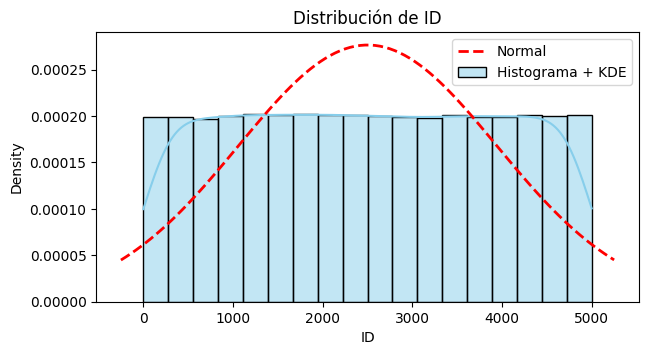

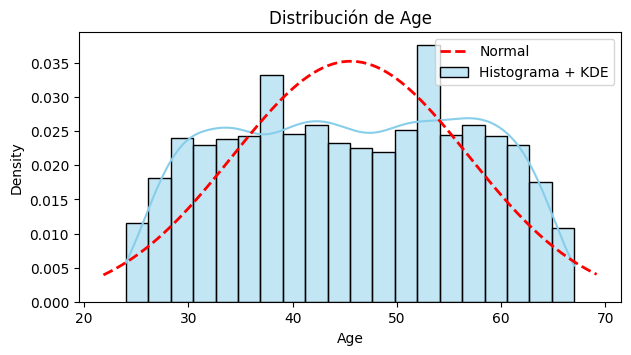

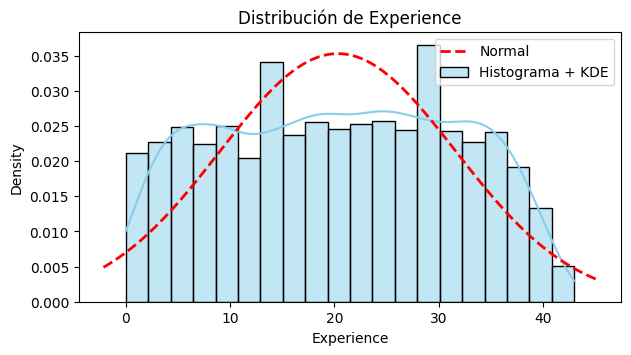

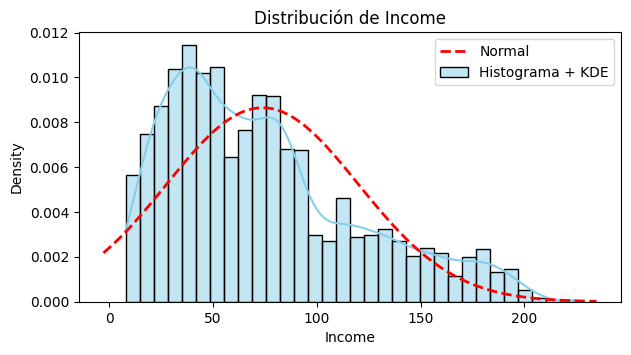

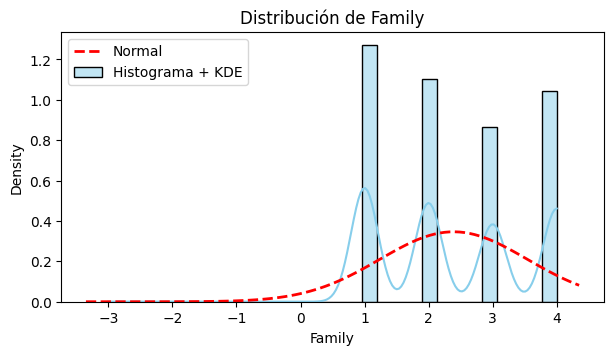

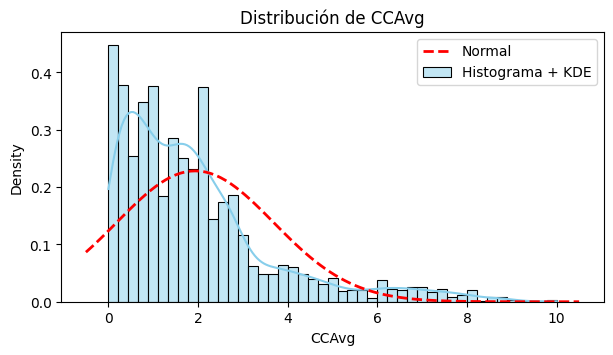

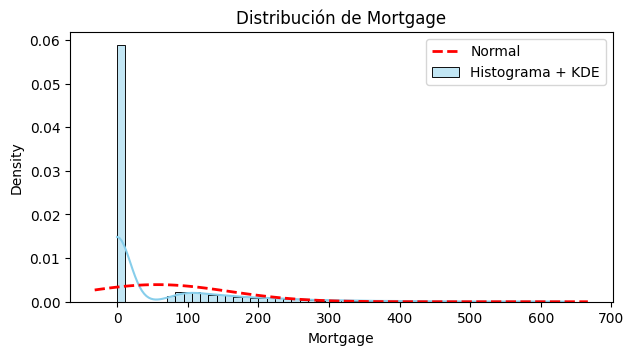

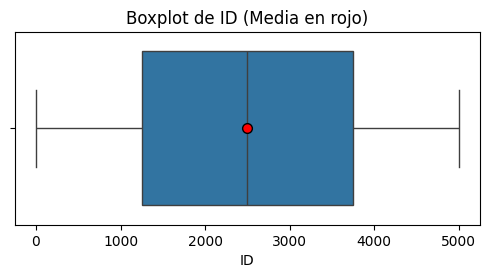

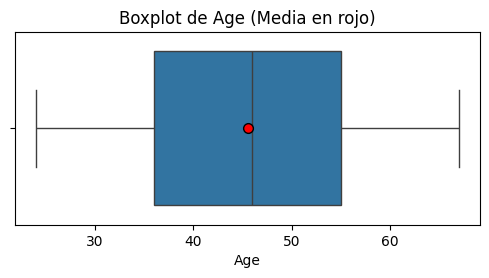

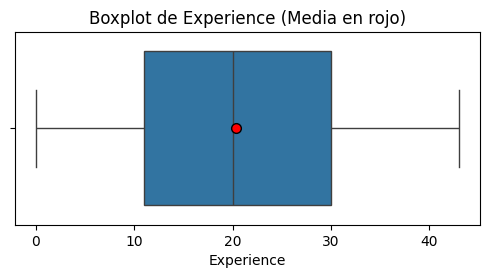

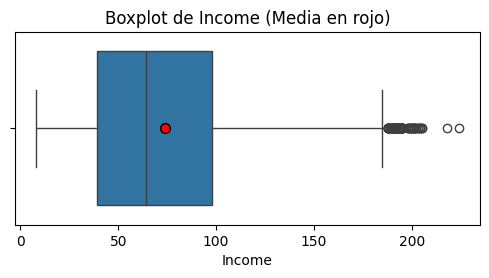

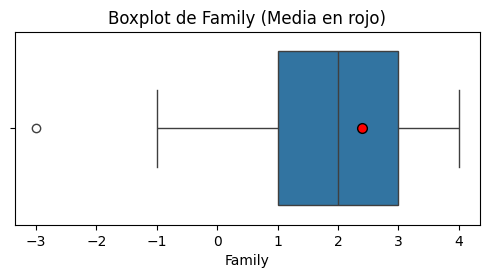

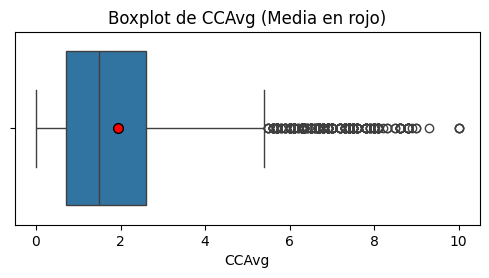

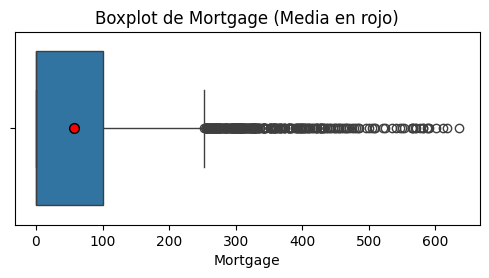

In [8]:
# Histogramas con KDE y curva de distribución normal de referencia
for col in num_cols:
    plt.figure(figsize=(7, 3.5))
    sns.histplot(loan_df[col], kde=True, stat="density", color="skyblue", label="Histograma + KDE")

    mu, std = loan_df[col].mean(), loan_df[col].std()
    xmin, xmax = plt.xlim()
    x = np.linspace(xmin, xmax, 100)
    plt.plot(x, norm.pdf(x, mu, std), 'r--', linewidth=2, label='Normal')

    plt.title(f'Distribución de {col}')
    plt.legend()
    plt.show()

# Boxplots individuales con la media marcada en rojo
for col in num_cols:
    plt.figure(figsize=(6, 2.5))
    sns.boxplot(x=loan_df[col], showmeans=True,
                meanprops={"marker":"o", "markerfacecolor":"red", "markeredgecolor":"black", "markersize":"7"})
    plt.title(f'Boxplot de {col} (Media en rojo)')
    plt.show()

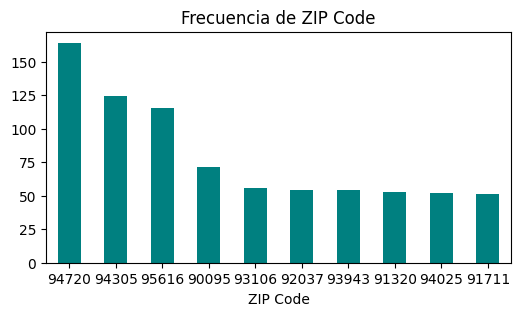

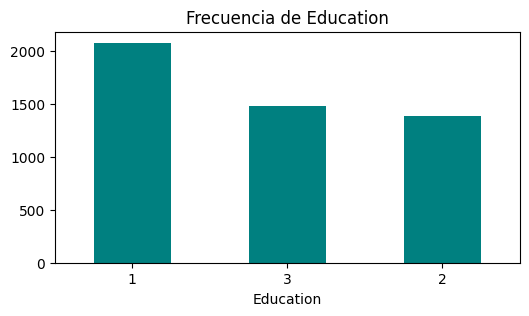

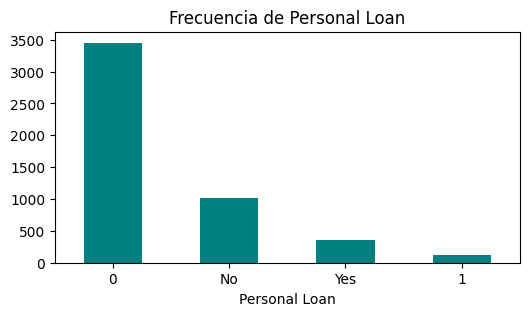

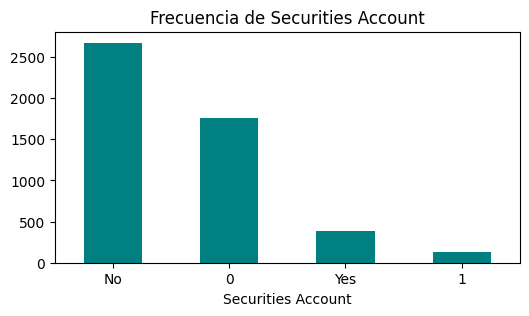

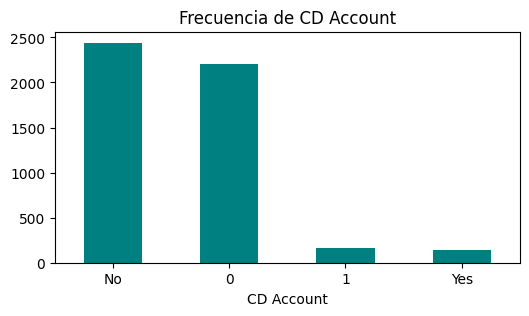

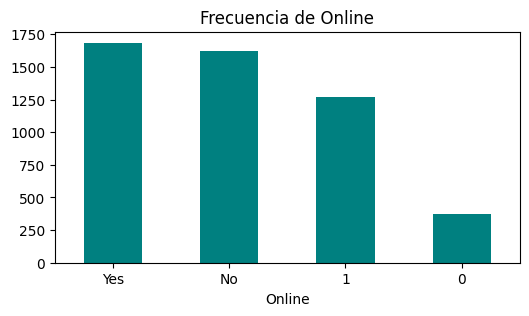

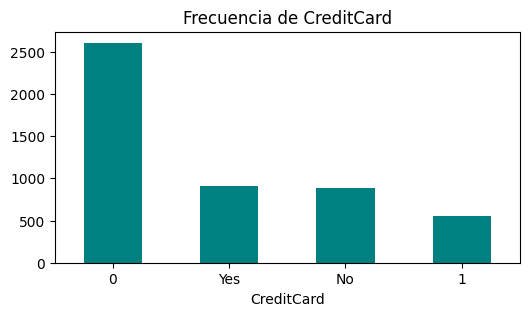

In [9]:
# Gráficos de barras para variables categóricas (limitando a top 10 si aplica)
for col in cat_cols:
    plt.figure(figsize=(6, 3))
    loan_df[col].value_counts().head(10).plot(kind='bar', color='teal')
    plt.title(f'Frecuencia de {col}')
    plt.xticks(rotation=0)
    plt.show()

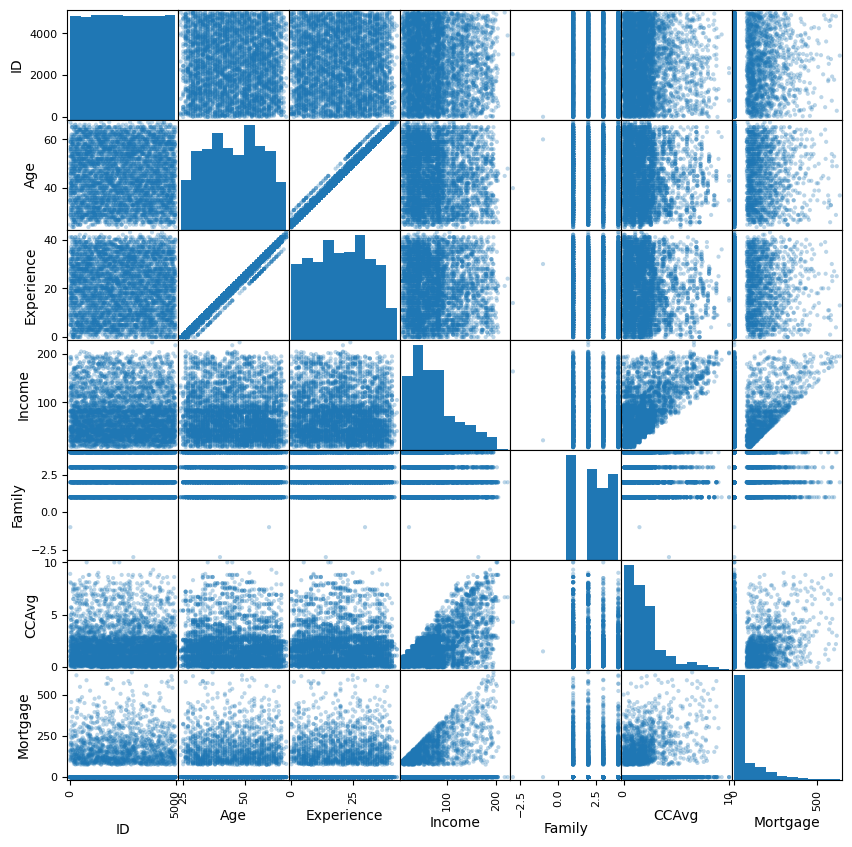

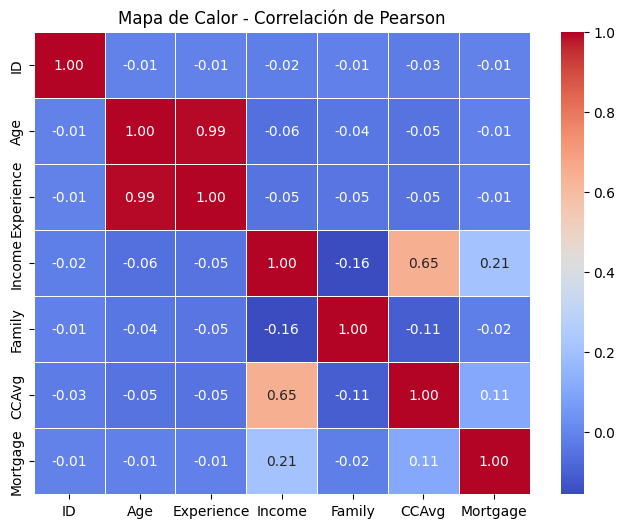

In [10]:
# Matriz de gráficos de dispersión
pd.plotting.scatter_matrix(loan_df[num_cols], figsize=(10, 10), alpha=0.3)
plt.show()

# Mapa de calor de correlación de Pearson
plt.figure(figsize=(8, 6))
corr = loan_df[num_cols].corr(numeric_only=True)
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Mapa de Calor - Correlación de Pearson')
plt.show()

/tmp/ipykernel_2015/3747523894.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Personal Loan', y=col, data=loan_df, palette='Set2')


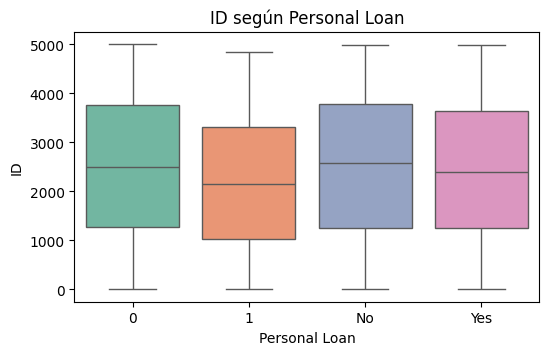

/tmp/ipykernel_2015/3747523894.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Personal Loan', y=col, data=loan_df, palette='Set2')


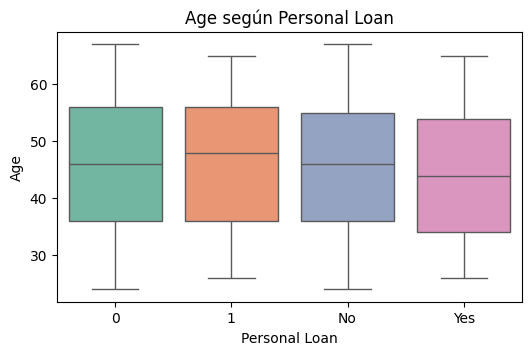

/tmp/ipykernel_2015/3747523894.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Personal Loan', y=col, data=loan_df, palette='Set2')


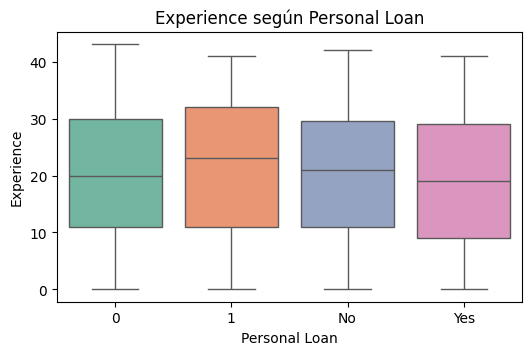

/tmp/ipykernel_2015/3747523894.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Personal Loan', y=col, data=loan_df, palette='Set2')


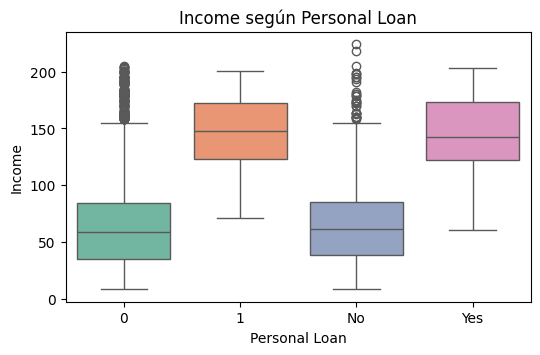

/tmp/ipykernel_2015/3747523894.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Personal Loan', y=col, data=loan_df, palette='Set2')


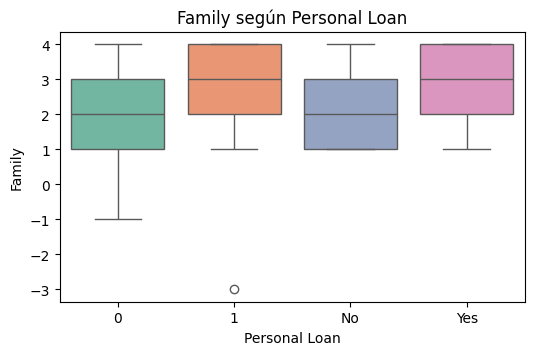

/tmp/ipykernel_2015/3747523894.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Personal Loan', y=col, data=loan_df, palette='Set2')


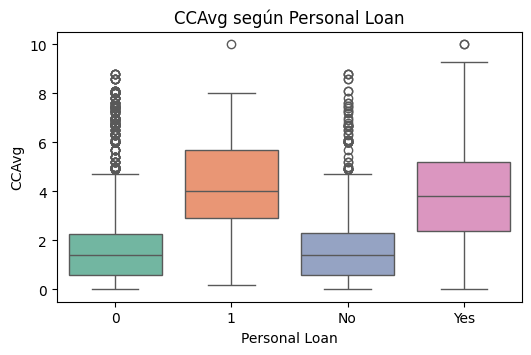

/tmp/ipykernel_2015/3747523894.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Personal Loan', y=col, data=loan_df, palette='Set2')


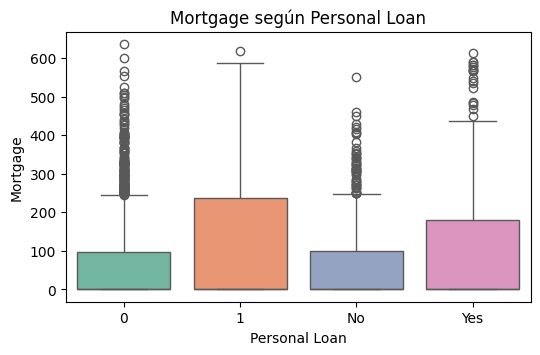

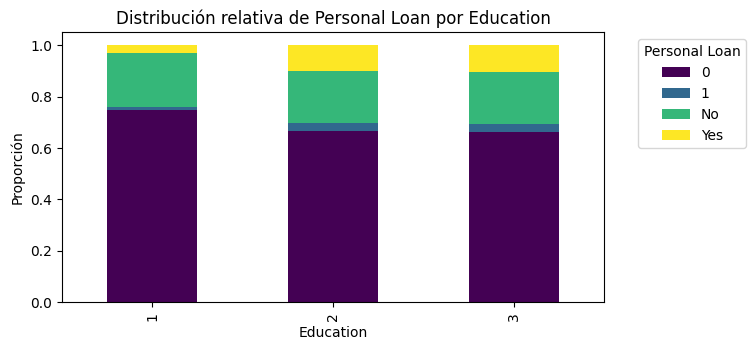

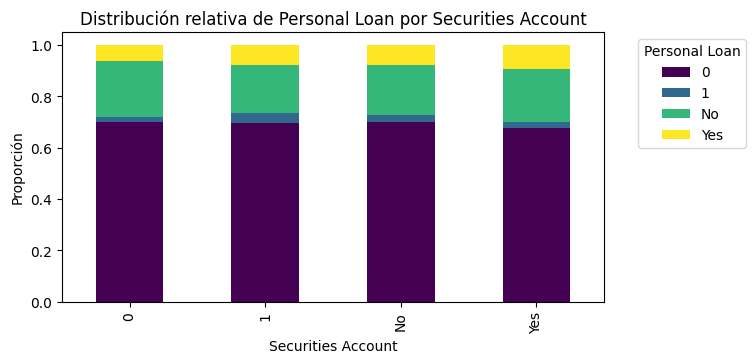

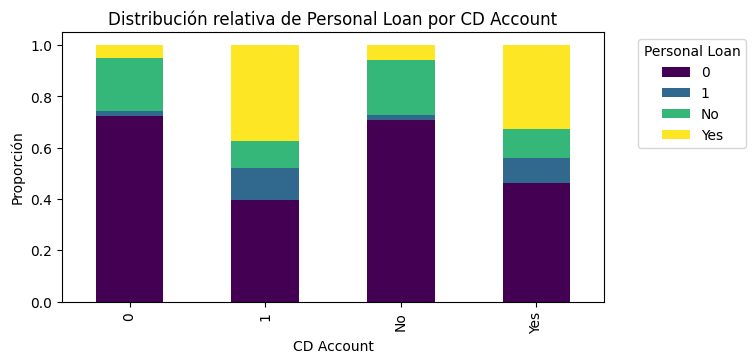

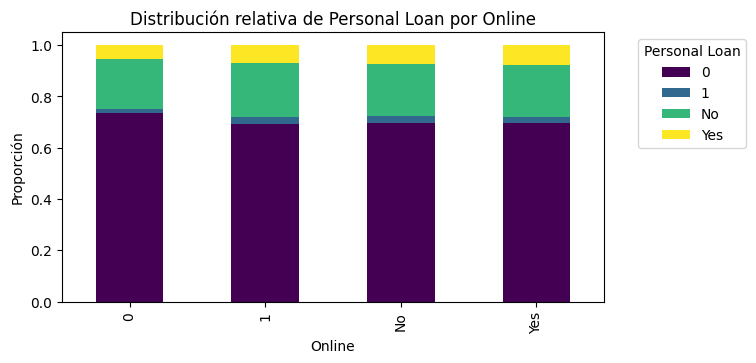

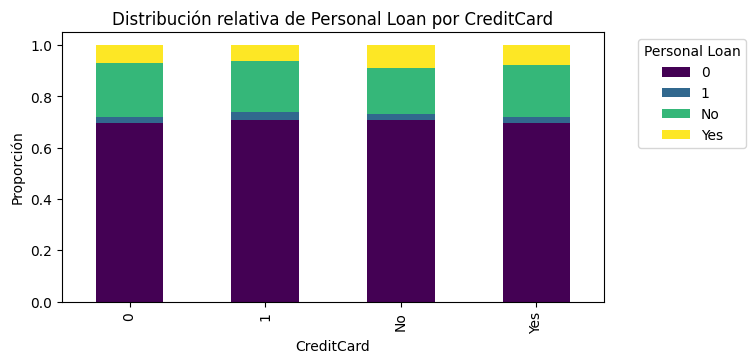

In [11]:
# Box plots de variables numéricas agrupadas por Personal Loan
for col in num_cols:
    plt.figure(figsize=(6, 3.5))
    sns.boxplot(x='Personal Loan', y=col, data=loan_df, palette='Set2')
    plt.title(f'{col} según Personal Loan')
    plt.show()

# Gráficos de barras apiladas relativas para variables categóricas
for col in cat_cols:
    if col not in ['ZIP Code', 'Personal Loan', 'ID']:
        cross_tab = pd.crosstab(loan_df[col], loan_df['Personal Loan'], normalize='index')
        cross_tab.plot(kind='bar', stacked=True, figsize=(7, 3.5), colormap='viridis')
        plt.title(f'Distribución relativa de Personal Loan por {col}')
        plt.ylabel('Proporción')
        plt.legend(title='Personal Loan', bbox_to_anchor=(1.05, 1))
        plt.show()